# Лабораторная работа 4. Параллельный перенос произвольной прямой в 3-ехмерном пространстве 

In [45]:
import numpy as np
import matplotlib.pyplot as plt

## Построим матрицы, которые участвуют в композиции

In [18]:
def translation_matrix(tx, ty, tz):
    """Матрица параллельного переноса T(t)."""
    return np.array([
        [1, 0, 0, tx],
        [0, 1, 0, ty],
        [0, 0, 1, tz],
        [0, 0, 0,  1]
    ], dtype=float)

In [19]:
def rot_x_matrix(cos_a, sin_a):
    """Матрица поворота вокруг оси X."""
    return np.array([
        [1,      0,       0, 0],
        [0,  cos_a,  -sin_a, 0],
        [0,  sin_a,   cos_a, 0],
        [0,      0,       0, 1]
    ], dtype=float)

In [20]:
def rot_y_matrix(cos_b, sin_b):
    """Матрица поворота вокруг оси Y."""
    return np.array([
        [ cos_b, 0, -sin_b, 0],
        [     0, 1,      0, 0],
        [ sin_b, 0,  cos_b, 0],
        [     0, 0,      0, 1]
    ], dtype=float)

In [21]:
def rot_z_matrix(phi):
    """Матрица поворота вокруг оси Z."""
    c, s = np.cos(phi), np.sin(phi)
    return np.array([
        [c, -s, 0, 0],
        [s,  c, 0, 0],
        [0,  0, 1, 0],
        [0,  0, 0, 1]
    ], dtype=float)

## Определим композицию

In [36]:
def get_rotation_matrix(P, v, phi):
    """
    Вычисляет цепочку матриц для поворота вокруг прямой (P, v) на угол phi.
    v должен быть единичным вектором.
    """
    # Инициализирем координаты единичного вектора и проекцию на YZ
    vx, vy, vz = v
    d = np.sqrt(vy**2 + vz**2)

    # Сдвиг из точки P -> O
    T_inv_P = translation_matrix(-P[0], -P[1], -P[2])
    T_P     = translation_matrix( P[0],  P[1],  P[2])

    # Поворот вокруг X для обнуления vy
    if d > 1e-9:
        cos_a, sin_a = vz / d, vy / d
    else:
        cos_a, sin_a = 1.0, 0.0
    R_x = rot_x_matrix(cos_a, sin_a)
    R_x_inv = rot_x_matrix(cos_a, -sin_a)

    # Поворот вокруг Y для совмещения с осью Z
    cos_b, sin_b = d, vx
    R_y = rot_y_matrix(cos_b, sin_b)
    R_y_inv = rot_y_matrix(cos_b, -sin_b)

    # Поворот вокруг Z на угол phi
    R_z = rot_z_matrix(phi)

    # Последовательная композиция
    return T_P @ R_x_inv @ R_y_inv @ R_z @ R_y @ R_x @ T_inv_P

In [37]:
def transform(M, points):
    """
    Применяет матрицу 4x4 к набору точек (N, 3).
    points: np.array(N,3),
    M: np.array(4,4)
    """
    #Добавляем столбец из единиц 
    pts_h = np.hstack([points, np.ones((len(points), 1))])  #pts_h.shape = (N,4)
    return (M @ pts_h.T).T[:, :3]   #.T[:, :3] - просто транспонируем результат к привычной форме. При помощи среза отбрасываем фиктивную координату

## Входные данные

In [38]:
P = np.array([1.0, 1.0, 1.0])
v = np.array([0.0, 0.0, 1.0])
v = v / np.linalg.norm(v)
phi = np.pi / 2

In [ ]:
segment = np.array([
    [2.0, 1.0, 1.0],    #точка A
    [2.0, 1.0, 3.0]     #точкуа B
])

## Применение матрицы поворота к прямой

In [52]:
M = get_rotation_matrix(P, v, phi)
rotated_segment = transform(M, segment)
print(f'Матрица M:\n {M}\n')
print(f'Повернутая на угол {np.degrees(phi):.0f}° прямая вокруг прямой L, которая проходит через точку P:{P} с единичным вектором v:{v} имеет координаты точек A и B\nДо поворота\n{segment}\nИ после поворота\n{rotated_segment} ')


Матрица M:
 [[ 6.12323400e-17 -1.00000000e+00  0.00000000e+00  2.00000000e+00]
 [ 1.00000000e+00  6.12323400e-17  0.00000000e+00 -1.11022302e-16]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]

Повернутая на угол 90° прямая вокруг прямой L, которая проходит через точку P:[1. 1. 1.] с единичным вектором v:[0. 0. 1.] имеет координаты точек A и B
До поворота
[[2. 1. 1.]
 [2. 1. 3.]]
И после поворота
[[1. 2. 1.]
 [1. 2. 3.]] 


## Визуализация (сгенерирована при помощи нейронки)

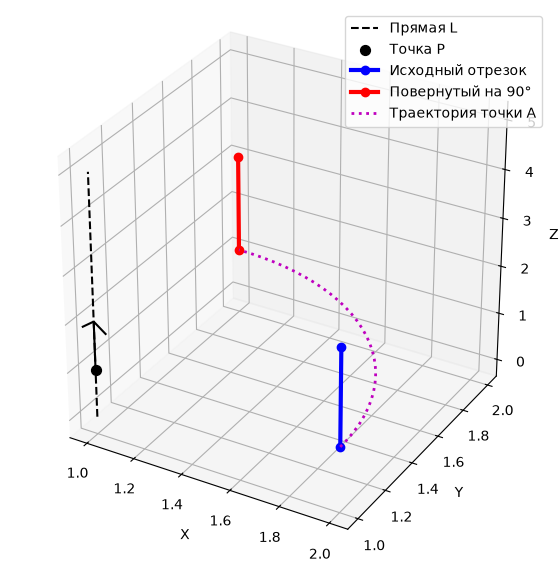

In [46]:
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

# Прямая L
t = np.linspace(-1, 4, 10)
line = P + np.outer(t, v)
ax.plot(line[:, 0], line[:, 1], line[:, 2], 'k--', linewidth=1.5, label='Прямая L')

# Точка P и вектор v
ax.scatter(*P, color='black', s=50, label='Точка P')
ax.quiver(*P, *v, length=1.0, color='black', arrow_length_ratio=0.2)

# Исходный отрезок (Синий)
ax.plot(segment[:, 0], segment[:, 1], segment[:, 2], 'b-o', linewidth=3, label='Исходный отрезок')

# Повернутый отрезок (Красный)
ax.plot(rotated_segment[:, 0], rotated_segment[:, 1], rotated_segment[:, 2], 'r-o', linewidth=3, label=f'Повернутый на {np.degrees(phi):.0f}°')

# Дуга траектории для проверки движения точки A
arc_angles = np.linspace(0, phi, 30)
arc_pts = [transform(get_rotation_matrix(P, v, a), segment[:1])[0] for a in arc_angles]
arc_pts = np.array(arc_pts)
ax.plot(arc_pts[:, 0], arc_pts[:, 1], arc_pts[:, 2], 'm:', linewidth=2, label='Траектория точки A')

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.legend()
ax.set_box_aspect([1, 1, 1])
plt.show()